TP 1 SOLUTION

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler,
    normalize, Binarizer, OrdinalEncoder, LabelEncoder, OneHotEncoder
)
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

ModuleNotFoundError: No module named 'numpy'

Exercise 1 : Exploring a tabular dataset and creating data splits

In [ ]:
D = pd.read_csv("../../data/Iris_Dataset.csv")
D.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
D.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [ ]:
D.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
# shape: (number of rows, number of columns)
print("Shape:", D.shape)

# columns: column names
print("Columns:", D.columns.tolist())

# head(): first five rows by default
D.head()

Shape: (150, 5)
Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
selected_features = D[["sepal_length", "petal_width"]]
selected_features.head()

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2


In [ ]:
selected_features.head(20)

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


In [ ]:
D_copy = D.copy()
print("Original shape:", D.shape)
print("Copy shape:", D_copy.shape)

Original shape: (150, 5)
Copy shape: (150, 5)


In [ ]:
X = D.drop(columns=["species"])
y = D["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (120, 4)
X_test:  (30, 4)
y_train: (120,)
y_test:  (30,)


In [ ]:
total = len(D)
print(f"Total observations: {total}")
print(f"Training observations: {len(X_train)} ({len(X_train)/total:.1%})")
print(f"Test observations: {len(X_test)} ({len(X_test)/total:.1%})")

print("\nClass proportions in the full dataset:")
display(y.value_counts(normalize=True).sort_index().rename("proportion"))

print("Class proportions in training set:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion"))

print("Class proportions in test set:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion"))

Total observations: 150
Training observations: 120 (80.0%)
Test observations: 30 (20.0%)

Class proportions in the full dataset:


species
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

Class proportions in training set:


species
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

Class proportions in test set:


species
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

Exercise 2 : Exploring text data

In [ ]:
with open("../../data/txt_file.txt", "r", encoding="utf-8") as file:
    text_lines = file.readlines()

print("Number of lines:", len(text_lines))

Number of lines: 6


In [ ]:
for line in text_lines:
    print(line.rstrip("\n"))

0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2


In [ ]:
import ssl
import certifi

print("Python SSL certificates:", ssl.get_default_verify_paths())
print("Certifi certificate file:", certifi.where())

Python SSL certificates: DefaultVerifyPaths(cafile=None, capath=None, openssl_cafile_env='SSL_CERT_FILE', openssl_cafile='C:\\Program Files\\Common Files\\SSL/cert.pem', openssl_capath_env='SSL_CERT_DIR', openssl_capath='C:\\Program Files\\Common Files\\SSL/certs')
Certifi certificate file: c:\Users\ADMIN\Downloads\TP ML\.venv312\Lib\site-packages\certifi\cacert.pem


In [ ]:
from sklearn.datasets import fetch_20newsgroups

try:
    newsgroups = fetch_20newsgroups(
        subset="train",
        remove=("headers", "footers", "quotes")
    )
    print("Dataset loaded successfully.")
except Exception as exc:
    newsgroups = None
    print("Could not load/download 20 Newsgroups.")
    print("Check your internet connection, or use a locally available copy.")
    print("Details:", exc)

Could not load/download 20 Newsgroups.
Check your internet connection, or use a locally available copy.
Details: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1010)>


In [ ]:
if newsgroups is not None:
    print("Number of documents:", len(newsgroups.data))
    print("Number of target labels:", len(newsgroups.target))
    print("Number of classes:", len(newsgroups.target_names))
    print("Target array shape:", newsgroups.target.shape)

In [ ]:
if newsgroups is not None:
    print(newsgroups.data[0][:2000])  # show the first 2,000 characters
    numeric_label = newsgroups.target[0]
    print("\nNumeric target:", numeric_label)
    print("Class name:", newsgroups.target_names[numeric_label])

In [ ]:
if newsgroups is not None:
    for index, class_name in enumerate(newsgroups.target_names):
        print(f"{index} -> {class_name}")

In [ ]:
if newsgroups is not None:
    lengths = [len(document.split()) for document in newsgroups.data]
    print("Shortest document (words):", min(lengths))
    print("Longest document (words):", max(lengths))
    print("Average document length (words):", round(np.mean(lengths), 2))

Exercise 3 : Detecting and handling missing values

In [ ]:
employees = pd.read_csv("../../data/employees.csv")

print("Shape:", employees.shape)

print("\nData types:")
print(employees.dtypes)

employees.head()

Shape: (1000, 8)

Data types:
First Name               str
Gender                   str
Start Date               str
Last Login Time          str
Salary                 int64
Bonus %              float64
Senior Management     object
Team                     str
dtype: object


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


In [ ]:
missing_before = employees.isna().sum()
display(missing_before.rename("missing values").to_frame())

,missing values
First Name,67
Gender,145
Start Date,0
Last Login Time,0
Salary,0
Bonus %,0
Senior Management,67
Team,43


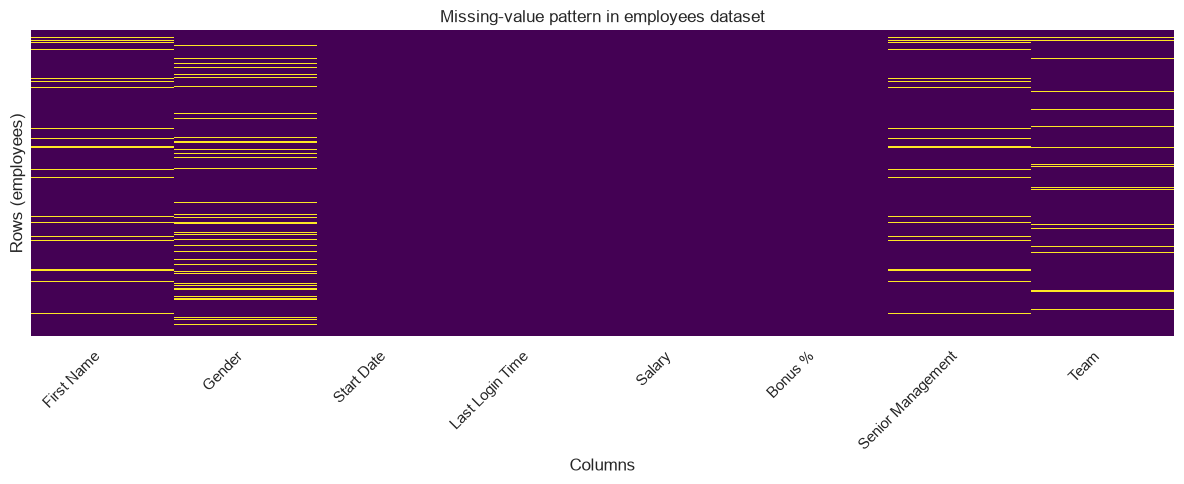

In [ ]:
plt.figure(figsize=(12, 5))
sns.heatmap(employees.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing-value pattern in employees dataset")
plt.xlabel("Columns")
plt.ylabel("Rows (employees)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
employees_work = employees.copy()

synthetic_row = {
    "First Name": "-",
    "Gender": "na",
    "Start Date": np.nan,
    "Last Login Time": np.nan,
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": np.nan,
    "Team": np.nan
}

employees_work = pd.concat(
    [employees_work, pd.DataFrame([synthetic_row])],
    ignore_index=True
)

print("New shape:", employees_work.shape)
employees_work.tail()

New shape: (1001, 8)


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
996,Phillip,Male,1/31/1984,6:30 AM,42392.0,19.675,False,Finance
997,Russell,Male,5/20/2013,12:39 PM,96914.0,1.421,False,Product
998,Larry,Male,4/20/2013,4:45 PM,60500.0,11.985,False,Business Development
999,Albert,Male,5/15/2012,6:24 PM,129949.0,10.169,True,Sales
1000,-,na,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
display(employees_work.isna().sum().rename("missing values").to_frame())
print("The literal '-' count:", (employees_work == "-").sum().sum())
print("The literal 'na' count:", (employees_work == "na").sum().sum())

,missing values
First Name,67
Gender,145
Start Date,1
Last Login Time,1
Salary,1
Bonus %,1
Senior Management,68
Team,44


The literal '-' count: 1
The literal 'na' count: 1


In [ ]:
# Rule: treat the exact strings '-' and 'na' (case-insensitive) as missing.
employees_work = employees_work.replace(
    {"-": np.nan, "na": np.nan, "NA": np.nan, "Na": np.nan}
)

display(employees_work.isna().sum().rename("missing values").to_frame())

,missing values
First Name,68
Gender,146
Start Date,1
Last Login Time,1
Salary,1
Bonus %,1
Senior Management,68
Team,44


In [ ]:
numeric_columns = employees_work.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = employees_work.columns.difference(numeric_columns).tolist()

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numeric columns: ['Salary', 'Bonus %']
Categorical columns: ['First Name', 'Gender', 'Last Login Time', 'Senior Management', 'Start Date', 'Team']


In [ ]:
employees_imputed = employees_work.copy()

# Numerical columns: replace missing values with each column's median
if numeric_columns:
    numeric_imputer = SimpleImputer(strategy="median")
    employees_imputed[numeric_columns] = numeric_imputer.fit_transform(
        employees_work[numeric_columns]
    )

# Categorical columns: replace missing values with each column's most frequent value
if categorical_columns:
    categorical_imputer = SimpleImputer(strategy="most_frequent")
    employees_imputed[categorical_columns] = categorical_imputer.fit_transform(
        employees_work[categorical_columns]
    )

print("Missing values after imputation:")
display(employees_imputed.isna().sum().rename("missing values").to_frame())
employees_imputed.tail()

Missing values after imputation:


,missing values
First Name,0
Gender,0
Start Date,0
Last Login Time,0
Salary,0
Bonus %,0
Senior Management,0
Team,0


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
996,Phillip,Male,1/31/1984,6:30 AM,42392.0,19.6750,False,Finance
997,Russell,Male,5/20/2013,12:39 PM,96914.0,1.4210,False,Product
998,Larry,Male,4/20/2013,4:45 PM,60500.0,11.9850,False,Business Development
999,Albert,Male,5/15/2012,6:24 PM,129949.0,10.1690,True,Sales
1000,Marilyn,Female,1/26/2005,1:35 PM,90428.0,9.8385,True,Client Services


In [ ]:
comparison = pd.DataFrame({
    "before imputation": employees_work.isna().sum(),
    "after imputation": employees_imputed.isna().sum()
})
display(comparison)

,before imputation,after imputation
First Name,68,0
Gender,146,0
Start Date,1,0
Last Login Time,1,0
Salary,1,0
Bonus %,1,0
Senior Management,68,0
Team,44,0


Exercise 4 : Feature scaling, binarization, and categorical encoding

Part A : Scaling and binarization

In [ ]:
M = np.array([
    [1, -1,  2],
    [2,  0,  0],
    [0,  1, -1]
], dtype=float)

print("Original matrix:")
print(M)

Original matrix:
[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]


In [ ]:
transformers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "RobustScaler": RobustScaler()
}

scaled_results = {}
for name, transformer in transformers.items():
    scaled_results[name] = transformer.fit_transform(M)
    print(f"\n{name}:")
    print(np.round(scaled_results[name], 3))

# normalize() acts on each sample (row) by default, unlike the scalers above.
scaled_results["normalize (rows)"] = normalize(M)
print("\nnormalize (rows):")
print(np.round(scaled_results["normalize (rows)"], 3))


StandardScaler:
[[ 0.    -1.225  1.336]
 [ 1.225  0.    -0.267]
 [-1.225  1.225 -1.069]]

MinMaxScaler:
[[0.5   0.    1.   ]
 [1.    0.5   0.333]
 [0.    1.    0.   ]]

MaxAbsScaler:
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]

RobustScaler:
[[ 0.    -1.     1.333]
 [ 1.     0.     0.   ]
 [-1.     1.    -0.667]]

normalize (rows):
[[ 0.408 -0.408  0.816]
 [ 1.     0.     0.   ]
 [ 0.     0.707 -0.707]]


Main idea of each method
- StandardScaler: subtracts each feature's mean and divides by its standard deviation; each column is transformed.
- MinMaxScaler: maps each feature to the range 0 to 1 by default.
- MaxAbsScaler: divides each feature by its maximum absolute value; values are typically in [-1, 1] and sparse data can remain sparse.
- RobustScaler: centers by the median and scales by the interquartile range, so it is less affected by outliers.
- normalize(M): normalizes each sample/row by default (L2 norm); it does not independently standardize each feature.

In [ ]:
threshold = 0.5
binarizer = Binarizer(threshold=threshold)
M_binary = binarizer.fit_transform(M)

print(f"Threshold: {threshold}")
print(M_binary)

Threshold: 0.5
[[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


Why scaling matters
Distance and margin-based methods such as k-nearest neighbors and support vector machines can be dominated by features with larger numeric scales. Scaling often helps gradient-based optimization too. Decision trees generally do not require scaling because their splits depend on feature ordering and thresholds, not distances between numeric values.

Part B : Encoding categorical variables

In [ ]:
categorical_data = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target": ["US", "France", "Japan", "Algeria"]
})
categorical_data

,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria


In [ ]:
input_columns = ["Feature 1", "Feature 2", "Feature 3"]
X_categories = categorical_data[input_columns]

ordinal_encoder = OrdinalEncoder()
X_ordinal = ordinal_encoder.fit_transform(X_categories)

print("Encoded input features:")
print(X_ordinal)
print("\nCategories for each feature:")
for column, categories in zip(input_columns, ordinal_encoder.categories_):
    print(f"{column}: {categories}")

X_ordinal_df = pd.DataFrame(
    X_ordinal, columns=[f"{column} encoded" for column in input_columns]
)
display(X_ordinal_df)

Encoded input features:
[[1. 3. 2.]
 [0. 2. 2.]
 [0. 1. 1.]
 [1. 0. 0.]]

Categories for each feature:
Feature 1: ['female' 'male']
Feature 2: ['from Africa' 'from Asia' 'from Europe' 'from US']
Feature 3: ['uses Chrome' 'uses Firefox' 'uses Safari']


,Feature 1 encoded,Feature 2 encoded,Feature 3 encoded
0,1.0,3.0,2.0
1,0.0,2.0,2.0
2,0.0,1.0,1.0
3,1.0,0.0,0.0


The codes assigned by OrdinalEncoder are category identifiers. Unless a feature truly has an ordered meaning, a code such as 0, 1, or 2 does not mean that one category is smaller, greater, better, or worse than another.

In [ ]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(categorical_data["Target"])

print("Encoded target:", y_encoded)
print("\nClass-name to numeric-label mapping:")
for class_name, numeric_label in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{class_name} -> {numeric_label}")

Encoded target: [3 1 2 0]

Class-name to numeric-label mapping:
Algeria -> 0
France -> 1
Japan -> 2
US -> 3


In [ ]:
# Use sparse_output=False in current scikit-learn versions.
# If your installed version is older, replace sparse_output=False with sparse=False.
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
y_onehot = onehot_encoder.fit_transform(categorical_data[["Target"]])

print("One-hot categories:", onehot_encoder.categories_)
print("One-hot target matrix:")
print(y_onehot)
print("One-hot column order:", onehot_encoder.get_feature_names_out(["Target"]))

One-hot categories: [array(['Algeria', 'France', 'Japan', 'US'], dtype=object)]
One-hot target matrix:
[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]
One-hot column order: ['Target_Algeria' 'Target_France' 'Target_Japan' 'Target_US']


Integer labels vs one-hot encoding

LabelEncoder represents each target class with one integer.
One-hot encoding creates one binary column per class; each row has a 1 in the column for its class and 0 in the other class columns.
For nominal input features, one-hot encoding is often preferable because arbitrary ordinal codes may accidentally suggest a ranking or distance between categories. For example, a model might incorrectly interpret category code 2 as “twice” category code 1.

Final conclusion
- Tabular data: use pandas to load, inspect, select, and split data.
- Text data: read files with the correct encoding; a text corpus stores documents and their class labels.
- Missing data: identify actual missing values and agreed placeholder strings, then choose an imputation strategy suitable for each column.
- Numerical data: scale features when the algorithm is sensitive to scale; row normalization is a different operation from feature scaling.
- Categorical data: encode input categories and target labels separately; choose one-hot encoding for nominal input features when arbitrary integer ordering would be misleading.
- Good practice: preserve the original data and prevent data leakage by fitting preprocessing only on training data when building a predictive model.